# Καθαρισμός με χρήση του OpusFilter 

Δεύτερη προσέγγιση για τον καθαρισμό του παράλληλου corpus. Χρησιμοποιούμε το [OpusFilter](https://github.com/Helsinki-NLP/OpusFilter) 3.3.1, που διαβάζει όλα τα βήματα από ένα configuration αρχείο (opusfilter.yaml). Το notebook τρέχει το pipeline και εξηγεί τα scores που υπολογίζονται σε κάθε βήμα.

*Σημείωση: Χρησιμοποιούμε Python 3.13, δεν μπορούμε να χρησιμοποιήσουμε 3.14 εξαιτίας μίας εξάρτησης του OpusFilter (opus-fast-mosestokenizer).*

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from opusfilter.opusfilter import OpusFilter
from opusfilter.util import count_lines, lists_to_dicts, yaml

## Εκτέλεση του pipeline

Κάθε φίλτρο είναι ξεχωριστό βήμα, ώστε το κάθε βήμα να αφήνει το δικό του αρχείο και να μπορούμε να μετρήσουμε τα ζεύγη. Αν τα αρχεία εξόδου υπάρχουν ήδη, το OpusFilter παραλείπει το βήμα. Για να ξεκινήσει από την αρχή, σβήνουμε τον φάκελο work.

In [2]:
with open("opusfilter.yaml") as f:
    config = yaml.load(f)

OpusFilter(config).execute_steps()

Directory "work" does not exist. It will be created.
1000000it [00:15, 64393.05it/s]
1000000it [00:04, 243683.48it/s]
940334it [00:03, 281648.61it/s]
100000it [00:00, 477769.39it/s]
100000it [00:00, 413602.74it/s]
100000it [00:03, 28487.89it/s]
100000it [00:01, 94401.35it/s]
100000it [00:09, 10091.78it/s]
100000it [00:00, 374767.48it/s]
100000it [00:00, 395405.56it/s]
38876it [00:01, 29860.94it/s]/Users/raftisk/Projects/sandbox/.venv/lib/python3.13/site-packages/opusfilter/filters.py:163: MarkupResemblesLocatorWarning: The input passed in on this line looks more like a filename than HTML or XML.

If you meant to use Beautiful Soup to parse the contents of a file on disk, then something has gone wrong. You should open the file first, using code like this:

    filehandle = open(your filename)

You can then feed the open filehandle into Beautiful Soup instead of using the filename.

However, if you want to parse some data that happens to look like a filename, then nothing has gone wrong:

## Ζεύγη προτάσεων που αφαιρούνται σε κάθε βήμα

Η στήλη initial pairs μετράει τα ζεύγη που μπαίνουν σε κάθε βήμα και το ποσοστό removed % υπολογίζεται ως προς αυτά. Η αφαίρεση των διπλότυπων προτάσεων στο pipeline γίνεται σε δύο βήματα: πρώτα στα ελληνικά (dedup_greek), μετά στα αγγλικά (dedup_english).

In [3]:
steps = ["norm", "dedup_greek", "dedup_english", "length", "ratio", "html", "script", "langid"]
sizes = [count_lines("ParaCrawl_subset.el-en.el")] + [count_lines(f"work/{step}.el") for step in steps]

stats = pd.DataFrame({
    "initial pairs": sizes[:-1],
    "removed": [before - after for before, after in zip(sizes, sizes[1:])],
}, index=steps)
stats["removed %"] = (stats["removed"] / stats["initial pairs"] * 100).round(2)
stats

,initial pairs,removed,removed %
norm,1000000,0,0.00
dedup_greek,1000000,59666,5.97
dedup_english,940334,7951,0.85
length,932383,169728,18.20
ratio,762655,477,0.06
html,762178,51,0.01
script,762127,75,0.01
langid,762052,403,0.05


## Κατανομές των scores

Το βήμα score έγραψε το score του κάθε φίλτρου για κάθε ζεύγος που έμεινε μετά το deduplication. Οι κατακόρυφες κόκκινες γραμμές στα διαγράμματα δείχνουν τα όρια (thresholds) που ορίσαμε στο yaml.

In [4]:
with open("work/scores.jsonl") as f:
    scores = pd.json_normalize([lists_to_dicts(json.loads(line)) for line in f])

scores = scores.rename(columns={
    "LengthFilter.0": "words_el", "LengthFilter.1": "words_en",
    "LengthRatioFilter": "ratio",
    "HtmlTagFilter.0": "html_el", "HtmlTagFilter.1": "html_en",
    "CharacterScoreFilter.0": "script_el", "CharacterScoreFilter.1": "script_en",
    "LangidFilter.0": "langid_el", "LangidFilter.1": "langid_en",
})
scores.describe().T[["count", "mean", "std", "min", "max"]].round(2)

,count,mean,std,min,max
ratio,932383.0,1.18,0.21,1.00,13.0
script_el,932383.0,1.00,0.00,0.83,1.0
script_en,932383.0,1.00,0.00,0.81,1.0
langid_el,932383.0,1.00,0.00,1.00,1.0
langid_en,932383.0,1.00,0.02,0.00,1.0
words_el,932383.0,16.26,12.90,1.00,196.0
words_en,932383.0,16.17,12.91,1.00,192.0


### Φίλτρα που εφαρμόστηκαν στις ελληνικές προτάσεις

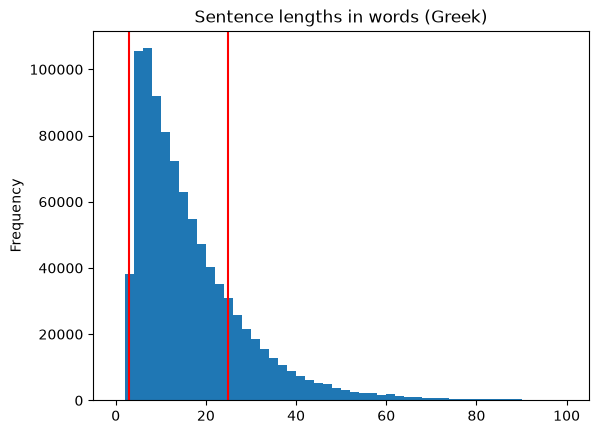

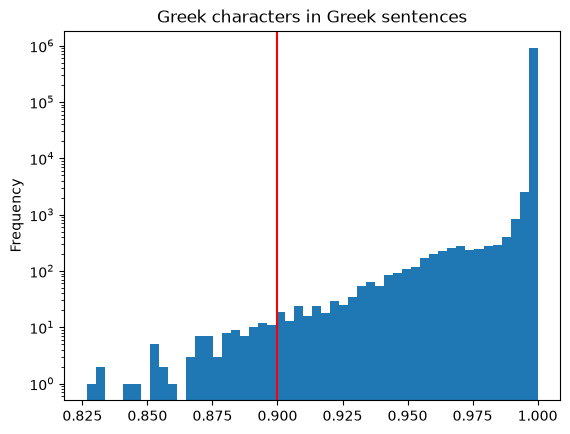

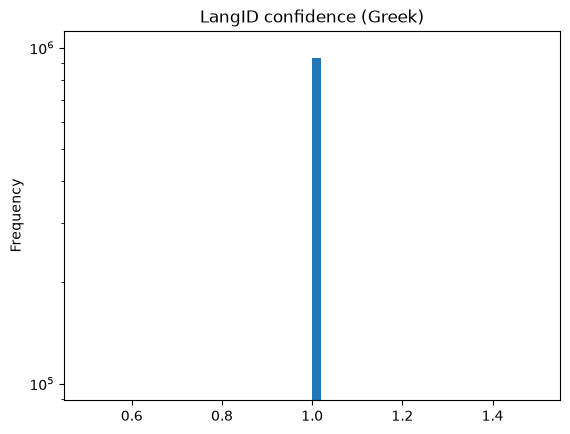

In [5]:
scores["words_el"].plot.hist(bins=50, range=(0, 100))
plt.axvline(3, color="red")
plt.axvline(25, color="red")
plt.title("Sentence lengths in words (Greek)")
plt.show()

scores["script_el"].plot.hist(bins=50, log=True)
plt.axvline(0.9, color="red")
plt.title("Greek characters in Greek sentences")
plt.show()

scores["langid_el"].plot.hist(bins=50, log=True)
plt.title("LangID confidence (Greek)")
plt.show()

### Φίλτρα που εφαρμόστηκαν στις αγγλικές προτάσεις

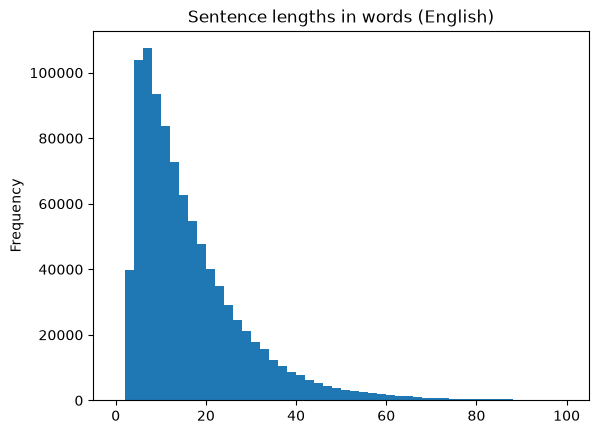

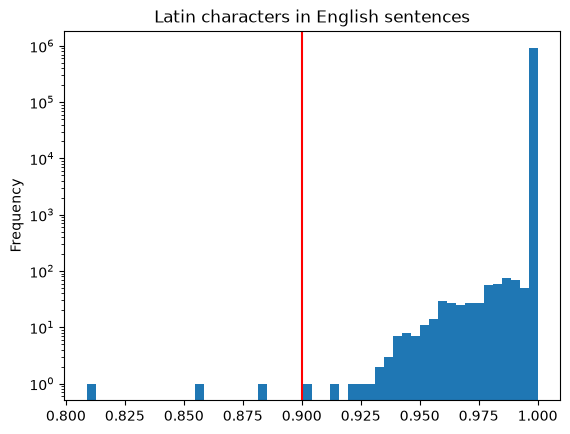

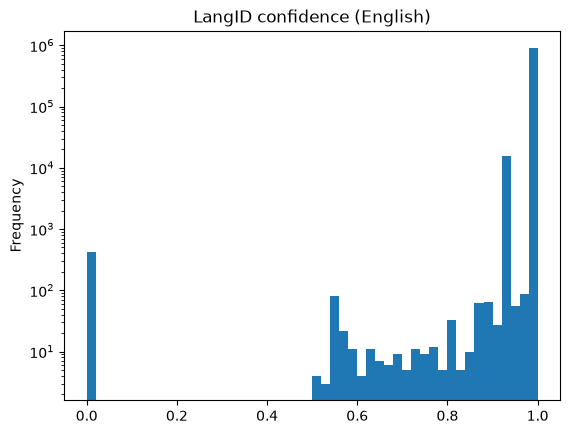

In [6]:
scores["words_en"].plot.hist(bins=50, range=(0, 100))
plt.title("Sentence lengths in words (English)")
plt.show()

scores["script_en"].plot.hist(bins=50, log=True)
plt.axvline(0.9, color="red")
plt.title("Latin characters in English sentences")
plt.show()

scores["langid_en"].plot.hist(bins=50, log=True)
plt.title("LangID confidence (English)")
plt.show()

### Length ratio
Το φίλτρο αυτό μετράει το λόγο μεταξύ των μηκών των αντιστοιχισμένων (μεταφρασμένων) προτάσεων. Για να πετύχουμε ακριβέστερες μεταφράσεις στα επόμενα στάδια, επιλέξαμε να κρατήσουμε ζεύγη με λόγο χαμηλότερο του 3.

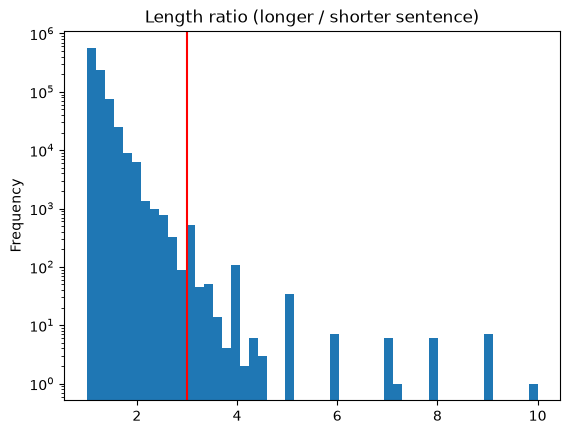

In [7]:
scores["ratio"].plot.hist(bins=50, range=(1, 10), log=True)
plt.axvline(3, color="red")
plt.title("Length ratio (longer / shorter sentence)")
plt.show()

## Παραδείγματα ζευγών που αφαιρέθηκαν

Για κάθε φίλτρο παραθέτουμε τρία τυχαία ζεύγη που απορρίφθηκαν.

In [8]:
with open("work/dedup_english.el", encoding="utf-8") as f:
    greek = f.read().splitlines()
with open("work/dedup_english.en", encoding="utf-8") as f:
    english = f.read().splitlines()
pairs = pd.DataFrame({"greek": greek, "english": english})

rejected = {
    "length": ~scores["words_el"].between(3, 25),
    "ratio": scores["ratio"] >= 3,
    "html": scores["html_el"] | scores["html_en"],
    "script": (scores["script_el"] < 0.9) | (scores["script_en"] < 0.9),
    "langid": (scores["langid_el"] == 0) | (scores["langid_en"] == 0),
}
pd.concat([pairs[mask].sample(3, random_state=42).assign(filter=name) for name, mask in rejected.items()])

,greek,english,filter
40027,Για τη διαχείριση εξαιρετικά κρίσιμων καταστάσ...,The Olympic Security Co-ordination Council is ...,length
446422,Προβλέπονται γενικά πρότυπα για τα ειδικά μέτρ...,General standards are laid down for the specif...,length
19350,Με την έ&υπνη διαχείριση συστήματος μετάδοσης ...,With intelligent powertrain management and an ...,length
710370,(Ένας βαθύτερος αναστεναγμός).,(A deeper sigh) But it is... how can one expla...,ratio
211100,"Συγκόλληση, εξώθηση, ζωγραφική","Brazing,Extrusion,Punching,CNC,Painting",ratio
82620,Για να εγκαταστήσετε μια...,Downloading...,ratio
307827,ΌλαΑΓΟΡΑΣΤΉΣΠΩΛΗΤΉΣ Εμφανίστε εταιρίες μόνον α...,AllBUYERSELLER Display companies only from: <N...,html
3637,"Ο Αφηγητής ανακοινώνει: ""< ώρα, την ημερομηνία...","Narrator announces: ""<time, date>, one event.""",html
724095,"Τα αρχεία του ανακοινώνονται ως εξής: ""Σημειωμ...","OneNote files are announced as: ""Notebook, <no...",html
351505,Η ηγεμονικÞ νοοτροπßα του δημüσιου τομÝα,The hegemonic mindset of public sector,script


## Σύγκριση με την αρχική προσέγγιση

Στο πρώτο notebook κρατάμε προτάσεις με 3 έως 25 λέξεις στα ελληνικά και length ratio (ελληνικά προς αγγλικά) από 0,3 έως 3. Εφαρμόζουμε τους ίδιους κανόνες στα ίδια ζεύγη, για να δούμε πόσο κοντά είναι το OpusFilter. Βλέπουμε ότι τα αποτελέσματα (πλήθος ζευγών μετά από καθαρισμό) είναι συγκρίσιμα.

In [9]:
words = pairs.apply(lambda column: column.str.split().str.len())
after_length = words[words["greek"].between(3, 25)]
after_ratio = after_length[(after_length["greek"] / after_length["english"]).between(0.3, 3)]

opusfilter = stats["initial pairs"] - stats["removed"]
pd.DataFrame({
    "pandas": [len(after_length), len(after_ratio)],
    "OpusFilter": opusfilter[["length", "ratio"]].to_numpy(),
}, index=["length", "ratio"])

,pandas,OpusFilter
length,762655,762655
ratio,762516,762178


## Τελικό δείγμα

300.000 ζεύγη από το καθαρισμένο corpus, με το ίδιο seed (42) που χρησιμοποιήσαμε στο πρώτο notebook.

In [10]:
with open("work/langid.el", encoding="utf-8") as f:
    greek = f.read().splitlines()
with open("work/langid.en", encoding="utf-8") as f:
    english = f.read().splitlines()
cleaned = pd.DataFrame({"greek": greek, "english": english})

sample = cleaned.sample(n=300000, random_state=42)
for language in ["greek", "english"]:
    with open(f"work/{language}_sentences.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(sample[language]) + "\n")

## Παρατηρήσεις

- Από τα 1.000.000 ζεύγη μένουν 761.649 (76,2%). Το όριο μήκους στα ελληνικά αφαιρεί 169.728 ζεύγη, δηλαδή το 71% όσων αφαιρούνται συνολικά. Τα duplicates αφαιρούν 67.617 ζεύγη (28%) και τα υπόλοιπα τέσσερα φίλτρα μαζί 1.006 (0,4%).
- Το φίλτρο script βρίσκει ελληνικό κείμενο με λάθος κωδικοποίηση, όπως το «ηγεμονικÞ νοοτροπßα».
- Το φίλτρο html πιάνει placeholders όπως το «&lt;time, date&gt;» και όχι πραγματικά tags.
- Το LangID, που διαλέγει μόνο ανάμεσα σε ελληνικά και αγγλικά, αφαιρεί 403 ζεύγη (0,05%). Και τα 3 παραδείγματα είναι αγγλικές προτάσεις με σύμβολα, δηλαδή false positives.
- Το φίλτρο μήκους δίνει ακριβώς τα ίδια αποτελέσματα με το πρώτο notebook. Στο length ratio η διαφορά είναι 338 ζεύγη, λόγω της διαφοράς στο κάτω όριο (0.3 vs 0.33)